<a href="https://colab.research.google.com/github/cristealarisa/ML-Seminar-CristeaLarisa/blob/main/Tema_Laborator_3_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Temă LP3 — Preprocesarea datelor (Titanic)

**Timp de lucru: maximum 15 minute** · lucru individual

Aplicați tehnicile din LP3 pe un set de date nou: **Titanic** — informații despre pasagerii navei (vârstă, sex, preț bilet, port de îmbarcare, punte) și dacă au supraviețuit (`survived`).

| Sarcina | Tema | Timp |
| --- | --- | --- |
| 1 | Valori lipsă: diagnostic și eliminare pe bază de prag | ~3 min |
| 2 | Imputarea valorilor lipsă | ~3 min |
| 3 | Asimetrie și transformare logaritmică | ~3 min |
| 4 | Outlieri (regula IQR) | ~3 min |
| 5 | Encoding și scalare | ~3 min |

> 💡 Completați celulele marcate `# TODO`. Nu e nevoie de cod perfect — contează să înțelegeți ce face fiecare pas.

### Pregătire — rulați celula (nu necesită modificări)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

titanic = sns.load_dataset('titanic')
df = titanic[['survived', 'pclass', 'sex', 'age', 'fare', 'embarked', 'deck']].copy()
df.head()

,survived,pclass,sex,age,fare,embarked,deck
0,0,3,male,22.0,7.2500,S,NaN
1,1,1,female,38.0,71.2833,C,C
2,1,3,female,26.0,7.9250,S,NaN
3,1,1,female,35.0,53.1000,S,C
4,0,3,male,35.0,8.0500,S,NaN


## Sarcina 1 — Valori lipsă (~3 min)

**1.1** Calculați procentul de valori lipsă pentru fiecare coloană, sortat descrescător.

**1.2** Eliminați coloanele cu **mai mult de 50%** valori lipsă. Care coloană dispare?

In [ ]:
# TODO 1.1 — procentul de valori lipsă pe coloană

# TODO 1.2 — eliminați coloanele cu > 50% valori lipsă


In [5]:
#1
(df.isna().mean() * 100).round(2).sort_values(ascending=False)


,0
deck,77.22
age,19.87
embarked,0.22
sex,0.00
pclass,0.00
survived,0.00
fare,0.00


In [7]:
#2
def drop_columns_with_high_nulls(df, threshold_percentage):
    """Coloanele cu mai mult de 50% val. lipsa """
    threshold = len(df) * (threshold_percentage / 100)
    dropped_columns = df.columns[df.isnull().sum() > threshold]
    df_cleaned = df.drop(columns=dropped_columns)
    return df_cleaned, dropped_columns

df_cleaned, dropped = drop_columns_with_high_nulls(df, 50)
print("Coloane eliminate:", list(dropped))
print("Coloanele ramase :", list(df_cleaned.columns))

Coloane eliminate: ['deck']
Coloane rămase  : ['survived', 'pclass', 'sex', 'age', 'fare', 'embarked']


## Sarcina 2 — Imputarea valorilor lipsă (~3 min)

**2.1** Imputați `age` cu **mediana** și `embarked` cu **valoarea cea mai frecventă** (modul).

**2.2** Verificați că nu mai există valori lipsă și comparați deviația standard a lui `age` înainte și după imputare. *(salvați înainte de imputare: `age_inainte = df['age'].copy()`)*

In [ ]:
# TODO 2.1 — imputare age (mediană) și embarked (mod)


# TODO 2.2 — verificare + comparație deviație standard


In [12]:
#2.1
from sklearn.impute import SimpleImputer

df_imp = df_cleaned.copy()
df_imp[['age']] = SimpleImputer(strategy='median').fit_transform(df_imp[['age']])
df_imp[['embarked']] = SimpleImputer(strategy='most_frequent').fit_transform(df_imp[['embarked']])



In [13]:
#2.2
print("Valori lipsa:", df_imp.isna().sum().sum())

comp = pd.DataFrame({
    'inainte': age_inainte.describe(),
    'dupa': df_imp['age'].describe()
})
print(comp.round(3))
print("\nStd inainte:", round(age_inainte.std(), 3))
print("Std dupa   :", round(df_imp['age'].std(), 3))

Valori lipsa: 0
       inainte     dupa
count  714.000  891.000
mean    29.699   29.362
std     14.526   13.020
min      0.420    0.420
25%     20.125   22.000
50%     28.000   28.000
75%     38.000   35.000
max     80.000   80.000

Std inainte: 14.526
Std dupa   : 13.02


## Sarcina 3 — Asimetrie și transformare logaritmică (~3 min)

**3.1** Calculați skewness-ul variabilei `fare`.

**3.2** Creați coloana `log_fare = np.log1p(fare)` și calculați skewness-ul ei. A ajutat transformarea?

**3.3** Desenați cele două histograme una lângă alta.

Skewness fare: 4.787
Skewness log_fare: 0.395


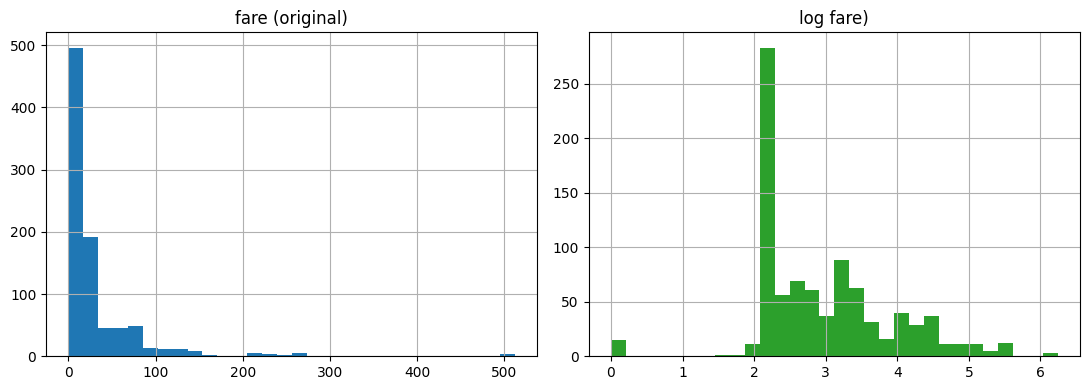

In [17]:
# TODO 3.1 — skewness fare
print("Skewness fare:", round(df_imp['fare'].skew(), 3))


# TODO 3.2 — coloana log_fare + skewness
df_imp['log_fare'] = np.log1p(df_imp['fare'])
print("Skewness log_fare:", round(df_imp['log_fare'].skew(), 3))


# TODO 3.3 — două histograme
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
df_imp['fare'].hist(ax=axes[0], bins=30)
axes[0].set_title('fare (original)')
df_imp['log_fare'].hist(ax=axes[1], bins=30, color='tab:green')
axes[1].set_title('log fare)')
plt.tight_layout()
plt.show()

## Sarcina 4 — Outlieri cu regula IQR (~3 min)

**4.1** Calculați limitele `[Q1 − 1,5·IQR ; Q3 + 1,5·IQR]` pentru `fare` și numărați outlierii.

**4.2** Limitați (clip) valorile extreme într-o coloană nouă, `fare_capped`, și afișați maximul înainte și după.

In [19]:
# TODO 4.1 — limite IQR + număr de outlieri
def limite_iqr(serie, k=1.5):
    q1, q3 = serie.quantile(0.25), serie.quantile(0.75)
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr
jos, sus = limite_iqr(df_imp['fare'])
n_out = ((df_imp['fare'] < jos) | (df_imp['fare'] > sus)).sum()
print("Limita inferioara:", round(jos, 2))
print("Limita superioara:", round(sus, 2))
print("Nr. outlieri:", n_out)

# TODO 4.2 — fare_capped (clip) + maxim înainte/după
df_imp['fare_capped'] = df_imp['fare'].clip(lower=jos, upper=sus)
print("Maxim_1:", df_imp['fare'].max())
print("Maxim_2 :", df_imp['fare_capped'].max())


Limita inferioara: -26.72
Limita superioara: 65.63
Nr. outlieri: 116
Maxim_1: 512.3292
Maxim_2 : 65.6344


## Sarcina 5 — Encoding și scalare (~3 min)

**5.1** Aplicați One-Hot Encoding pe `sex` și `embarked` (cu `drop_first=True`, `dtype=int`).

**5.2** Standardizați `age` și `fare_capped` cu `StandardScaler`. Verificați că media ≈ 0 și deviația standard ≈ 1.

In [20]:
# TODO 5.1 — One-Hot Encoding pentru sex și embarked
dummies = pd.get_dummies(df_imp[['sex', 'embarked']], drop_first=True, dtype=int)
print(dummies.head())
print("Coloane noi:", list(dummies.columns))

# TODO 5.2 — StandardScaler pentru age și fare_capped + verificare medie/std

scaler = StandardScaler()
X_std = pd.DataFrame(
    scaler.fit_transform(df_imp[['age', 'fare_capped']]),
    columns=['age', 'fare_capped']
)
print(X_std.describe().loc[['mean', 'std']].round(3))

   sex_male  embarked_Q  embarked_S
0         1           0           1
1         0           0           0
2         0           0           1
3         0           0           1
4         1           0           1
Coloane noi: ['sex_male', 'embarked_Q', 'embarked_S']
        age  fare_capped
mean  0.000        0.000
std   1.001        1.001


## Întrebare de reflecție (1–2 propoziții)

*De ce am imputat `age`, dar am eliminat `deck`?*

*Răspunsul tău:* Lipsesc 77% din valorile lui deck, daca am imputa pentru aceasta variabila, valorile introduse nu ar reprezenta in mod corect ulterioarele analize. Pentru variabila age lipsesc doar 20% din valori, astfel, imputarea nu prezinta un risc la fel de mare.